# Agent

- 将所有 Agent 的创建方式统一为一个入口：create_agent()

In [ ]:
from unittest import result

from anthropic.types.shared import overloaded_error
from charset_normalizer.cd import coherence_ratio
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_experimental.graph_transformers.llm import system_prompt
from openai.types.shared_params import reasoning_effort

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek")
agent=create_agent(
    model=model,
    tools=[tool1,tool2],
    system_prompt="Agent的行为命令"
)

result=agent.invoke({
    "messages":[{"role":"user","content":"问题"}]
})

## create_agent完整参数
```
    from langchain.agents import create_agent

    agent = create_agent(
        model: str | BaseChatModel, # 必需：聊天模型
        tools: List[BaseTool], # 必需：工具列表
        *,
        system_prompt: str = "", # 系统提示词
        middleware: Seguence[AgentMiddleware[StateT_co, ContextT]] = () # 中间件
        interrupt_before: List[str] = None, # 在某些工具前暂停（人机协作）
        interrupt_after: List[str] = None, # 在某些工具后暂停
        debug: bool = False # 调试模式
        name: str 丨 None = None, # 设置模型名称
    )
```

### 传入模型

agent底层实现是一个图结构

<class 'langgraph.graph.state.CompiledStateGraph'>


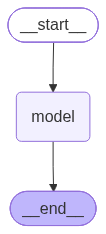

In [1]:
# Agent根据传入的模型字符串，自主创建对象

from langchain.agents import  create_agent
from dotenv import load_dotenv

load_dotenv(override=True)

agent=create_agent("deepseek-flash")
print(type(agent))

from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

<class 'langgraph.graph.state.CompiledStateGraph'>


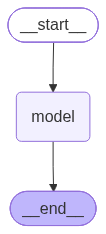

In [2]:
# 传入模型对象
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
import os

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek"
)
agent = create_agent(model)
print(type(agent))
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 调用agent

### agent.invoke() 是最基本的同步调用方式。会阻塞程序执行直到看到最终结果

In [6]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
from rich import  print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek"
)

agent=create_agent(model)
response=agent.invoke({"messages":["你好"]}) #默认是HumanMessage
print(type(response))
rprint(response)
print(response["messages"][-1].content)

<class 'dict'>


{
    'messages': [
        HumanMessage(
            content='你好',
            additional_kwargs={},
            response_metadata={},
            id='f043a09f-855e-479e-8e69-25be6ee5e492'
        ),
        AIMessage(
            content='你好！很高兴见到你 
😊\n\n有什么我可以帮忙的吗？无论是聊天、解答问题、写作、学习还是其他方面，我都很乐意帮你。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user just said "你好" (Hello) in Chinese. I should respond warmly in 
Chinese and offer help.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 55,
                    'prompt_tokens': 31,
                    'total_tokens': 86,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 23,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 31
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '2f9c7a0a-06a5-4200-b7db-76a371ea45a3',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1cfea-b8ac-775a-9218-f8cd610e8c15-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 31,
                'output_tokens': 55,
                'total_tokens': 86,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 23}
            }
        )
    ]
}

你好！很高兴见到你 😊

有什么我可以帮忙的吗？无论是聊天、解答问题、写作、学习还是其他方面，我都很乐意帮你。


In [8]:
#在messages列表开头加入system角色定义Agent行为

from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
from rich import  print as rprint

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek"
)

agent=create_agent(model)
resp=agent.invoke({"messages":[
    {"role":"system","content":"你是一名耐心的老师"},
    {"role":"user","content":"1+2+n？"}
]})
rprint(resp)

{
    'messages': [
        SystemMessage(
            content='你是一名耐心的老师',
            additional_kwargs={},
            response_metadata={},
            id='1da983de-0b8f-4d63-84af-8e66181643de'
        ),
        HumanMessage(
            content='1+2+n？',
            additional_kwargs={},
            response_metadata={},
            id='bbabb45a-76d8-41bf-bb52-4f7aadfb8e8d'
        ),
        AIMessage(
            content='如果 \\(n\\) 是一个数（变量），那么：\n\n\\[\n1+2+n=3+n=n+3\n\\]\n\n如果你告诉我 \\(n\\) 
等于几，我就可以帮你算出具体结果。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': '我们需要回答用户中文“1+2+n？”这看起来是一个数学表达式问题。可能用户想问 1+2+n
等于多少？需要澄清 n 是变量，所以等于 n+3。也可能是在问“1+2+n？”简单。需要以老师耐心语气。回答：如果 n 
是变量，1+2+n = 3+n = n+3。若 n 有具体数值代入。可能需要解释。注意用户用“？”可能期待。最终简洁。'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 145,
                    'prompt_tokens': 39,
                    'total_tokens': 184,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 102,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 39
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '08645858-8558-4a1b-8959-822198bf4084',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1cfed-58fc-736d-8f31-33def52b5d38-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 39,
                'output_tokens': 145,
                'total_tokens': 184,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 102}
            }
        )
    ]
}

# 绑定工具

langchain内置工具
![image.png](images/tools.png)

In [11]:
from langchain.agents import  create_agent
from langchain.tools import  tool
from rich import print as rprint

@tool(parse_docstring=True)
def get_weather(city:str)->str:
    """
    天气查询工具

    Args:
        city:城市名称
    """

    return f"{city}的天气为晴朗，25度"

agent=create_agent(model=model,
                   tools=[get_weather])

response=agent.invoke({"messages":[
    {"role":"system","content":"你是一个天气查询助手，只回答天气相关的问题，其他的回复不知道"},
   # {"role":"user","content":"1+1=？"}
    {"role":"user","content":"北京的天气如何呢"}
]})

rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个天气查询助手，只回答天气相关的问题，其他的回复不知道',
            additional_kwargs={},
            response_metadata={},
            id='55d8c752-c4dd-4ef3-875f-48caab2e780b'
        ),
        HumanMessage(
            content='北京的天气如何呢',
            additional_kwargs={},
            response_metadata={},
            id='9e41eedd-4757-4589-b853-70b652684895'
        ),
        AIMessage(
            content='',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': "The user asks about Beijing's weather. I should call the weather tool."
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 54,
                    'prompt_tokens': 313,
                    'total_tokens': 367,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 15,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128},
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 185
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '27ed074c-da4e-415a-a737-ddda781a58a3',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1cff6-2e00-743b-a2f4-d17bbd7ddaf8-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_00_rM5bV41GZRPGG5NyViEJ0873',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 313,
                'output_tokens': 54,
                'total_tokens': 367,
                'input_token_details': {'cache_read': 128},
                'output_token_details': {'reasoning': 15}
            }
        ),
        ToolMessage(
            content='北京的天气为晴朗，25度',
            name='get_weather',
            id='1f51e3e3-82fd-4237-bfac-d770825ab1d0',
            tool_call_id='call_00_rM5bV41GZRPGG5NyViEJ0873'
        ),
        AIMessage(
            content='北京今天是晴天，气温25度，天气不错呢～出门记得做好防晒哦。',
            additional_kwargs={'refusal': None, 'reasoning_content': ''},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 19,
                    'prompt_tokens': 386,
                    'total_tokens': 405,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128},
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 258
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '17335071-80a2-40f5-a787-19f1e294350f',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1cff6-34a6-71ff-844c-3f8d538fe9f9-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 386,
                'output_tokens': 19,
                'total_tokens': 405,
                'input_token_details': {'c

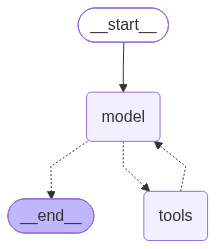

In [12]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [13]:
from langchain_tavily import  TavilySearch
from dotenv import load_dotenv
import os
load_dotenv(override=True)

web_search=TavilySearch(
    tavily_api_key=os.getenv("TAILLY_API_KEY"),
    max_results=2
)

web_search.invoke("请问南京邮电大学2026年毕业生有多少人去了bat")

{'query': '请问南京邮电大学2026年毕业生有多少人去了bat',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.163.com/dy/article/L9UAM5FN055683JA.html',
   'title': '南京邮电大学就业率是多少？这份数据比传言更有说服力|南京邮电大学|本科生|毕业生|民办本科_手机网易网',
   'content': '# 南京邮电大学就业率是多少？这份数据比传言更有说服力\n\n志愿研究院\n\n关于南京邮电大学的就业，坊间说法很多，但最可信的还是学校自己公布的数。近年来本科毕业生去向落实率稳定在95%以上；2025届毕业生中本科深造率超过53%，意味着每两名本科生就有一名继续读研或出国；保研率方面，2025届达到11.32%，2026届推免人数预计增至775人，保研率有望突破13%，呈逐年上升的态势。就业率稳、深造率高、薪资后劲足，这三个特征叠在一起，才是这所学校真正的竞争力。\n\n一、就业基本盘：落实率稳，王牌专业近乎全员就业\n\n先看基本面。2025届学校毕业生共8444人，其中本科生5589人、硕士研究生2774人、博士研究生81人。通信工程、电子信息等王牌专业的去向落实率接近满分，几乎实现毕业即就业。从单位规模看，毕业生就业主要集中在1001人及以上规模的用人单位，大型企业占比很高——这一点很关键，因为它决定了职业起点的高度和后续发展的稳定性。\n\n二、行业对口度，才是高就业率的真正底气 [...] 高就业率不是偶然，而是行业对口度高的必然结果。就业量最大的行业是信息传输、软件和信息技术服务业，本科生占比接近45%；细分行业中，计算机通信和其他电子设备制造业占20%、软件和信息技术服务业占17%、电信广播电视和卫星传输服务占15%、互联网和相关服务占8%。换句话说，毕业生的去向高度集中在国家战略急需的新一代信息技术领域，而这些领域的人才需求仍在扩张。学校还总结出三个特点：去向集中在大企业、信息底色足、留苏比例高。\n\n三、产教融合：把课堂搬进产业园区\n\n就业质量高的背后，是极具前瞻性的育人体系。学校推行驻入园区、嵌入产业、融入企业的产教融合新模式，

In [14]:
from langchain.agents import  create_agent
from langchain.tools import  tool
from langchain_tavily import TavilySearch
from rich import print as rprint

web_search=TavilySearch(max_results=2)

agent=create_agent(model=model,
                   tools=[web_search])

response=agent.invoke({"messages":[
    {"role":"system","content":"你是一个万能的查询助手，可以查询到所有问题"},
   # {"role":"user","content":"1+1=？"}
    {"role":"user","content":"请问南京邮电大学2026年毕业生有多少人去了bat"}
]})

rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个万能的查询助手，可以查询到所有问题',
            additional_kwargs={},
            response_metadata={},
            id='9d957a55-293e-4f05-9a97-70a4943cbdba'
        ),
        HumanMessage(
            content='请问南京邮电大学2026年毕业生有多少人去了bat',
            additional_kwargs={},
            response_metadata={},
            id='119f434f-e246-4495-a02f-6853de606daf'
        ),
        AIMessage(
            content='我来帮你查询相关信息。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user asks: "How many graduates of Nanjing University of Posts and 
Telecommunications (南京邮电大学) in 2026 went to BAT (Baidu, Alibaba, Tencent)?" \n\n2026 graduates - it\'s 2025 
now presumably, so 2026 graduates\' employment data wouldn\'t be complete yet. Let me search.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 214,
                    'prompt_tokens': 1850,
                    'total_tokens': 2064,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 70,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 1850
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '92201932-bb3d-448a-a77b-cfa2e0999fa6',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1cffc-c5a8-7131-afb4-8ad690ac8e77-0',
            tool_calls=[
                {
                    'name': 'tavily_search',
                    'args': {
                        'query': '南京邮电大学 2026届毕业生 就业质量报告 BAT 百度 阿里 腾讯',
                        'search_depth': 'advanced'
                    },
                    'id': 'call_00_gwUTZ1DVMxbOVl9VsveI7988',
                    'type': 'tool_call'
                },
                {
                    'name': 'tavily_search',
                    'args': {
                        'query': '南京邮电大学 毕业生 就业质量报告 华为 腾讯 阿里 百度 人数',
                        'search_depth': 'advanced'
                    },
                    'id': 'call_01_20cOQGFaKiLcQ68yUQgA4115',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 1850,
                'output_tokens': 214,
                'total_tokens': 2064,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 70}
            }
        ),
        ToolMessage(
            content='{"query": "南京邮电大学 2026届毕业生 就业质量报告 BAT 百度 阿里 腾讯", "follow_up_questions": 
null, "answer": null, "images": [], "results": [{"url": "https://www.eefocus.com/article/1854585.html", "title": 
"南邮2024年就业报告，华为202人！ - 与非网", "content": 
"电子硬件助手\\n元器件查询\\n\\n热搜\\n\\n搜索历史清空\\n\\n加入星计划，您可以享受以下权益：\\n\\n产业图谱\\n\\n# 
南邮2024年就业报告，华为202人！\\n\\n南京邮电大学于 2025 年 6 月 20 日在其公众号公布了 2024 
届毕业生就业报告。报告显示，2024 届毕业生总数达 8048 人，其中本科生有 5358 人，研究生为 2690 
人。\\n\\n从就业方向来看，南邮毕业生的去向主要集中在通信、信息科技、互联网、金融等领域。通信行业作为南邮毕业生的传
统就业高地，通信运营商成为吸纳人才的主力军。中国电信、中国移动、中国联通三家大型电信运营商共吸纳 789 
名南邮毕业生，其中中国电信录用 406 人，中国移动录用 284 人，中国联通录用 99 人。通信设备企业同样是招聘大户，华为以 
202 人的录用数量遥遥领先，中兴、小米分别录用 77 人、55 人，这些企业为毕业生提供了参与 5G 
技术研发、通信设备制造等前沿领域工作的机会 
。\\n\\n在互联网领域，阿里巴巴、腾讯、百度等知名大厂也向南邮毕业生抛出橄榄枝，为其提供互联网技术研发、产品设计、运
营管理等关键岗位，助力毕业生在数字经济浪潮中施展才华。除企业外，不少毕业生选择进入政府机构，参与通信政策制定、技术
标准规范、行业监管等工作；或是投身科研院所，协助完成国家重点研究项目，推动学科前沿研究成果转化。中国邮政、中国电科
等央企和国企，也凭借稳定的工作环境，吸引了众多南邮学子加入。 [...] 在就业质量上，南邮表现出色。2023 
届本科毕业生的年终就

In [15]:
print(response["messages"][-1].content)

## 直接结论

**目前查不到“南邮2026届毕业生有多少人去了BAT”的官方数据，因为2026届毕业生还没毕业，就业质量报告尚未发布。**

### 一、为什么没有这个数据

- 南京邮电大学2026届毕业生正常于 **2026年6月毕业**。学校的《毕业生就业质量年度报告》一般在毕业当年年底至次年（即2026年末—2027年中）才公布，其中才会统计“主要就业单位录用人数”。
- 所以现在（2026届秋招/春招进行中）任何“2026届去BAT多少人”的具体数字都只能是传闻，没有官方统计口径。

### 二、能查到的2026届相关信息：只有生源规模

南邮就业信息网公布的2026届生源信息：
- 毕业生总数 **约9075人**（另有通知口径为9184人，两个版本略有差异）
- 其中本科毕业生 **6149人**、硕士 **2827人**、博士 **99人**

（来源：南京邮电大学就业信息网 njupt.91job.org.cn）

### 三、可参考的最近官方数据：2024届

南邮2024届就业质量报告（2025年6月20日发布，共8048人：本科5358人、研究生2690人）中公布的主要录用人数：

| 单位 | 录用人数 |
|---|---|
| 中国电信 | 406人 |
| 中国移动 | 284人 |
| 华为 | 202人 |
| 中国联通 | 99人 |
| 中兴 | 77人 |
| 小米 | 55人 |

关于BAT：报告只笼统表述“阿里巴巴、腾讯、百度等知名互联网大厂也向南邮毕业生抛出橄榄枝”，**并未单独公布百度、阿里、腾讯各自的具体录用人数**。南邮历年报告的主要就业单位统计表一般只列到录用规模较大的几十家单位，BAT中单家录用人数通常较小（多在个位数到二三十人量级），往往不进入单独列示的榜单。

### 四、旁证参考（注意别混淆）

北京邮电大学2025届公布：“822人入职阿里巴巴、腾讯、美团、字节跳动、百度等互联网头部企业”，即“互联网头部企业合计822人”。北邮规模与互联网行业偏好都明显强于南邮；不要把这一数字当成南邮的数据，也不要当成BAT一家的数字。

### 五、想拿到准确答案的建议

1. **2026年底—2027年中**，关注“南京邮电大学就业信息网（njupt.91job.org.cn）”以及“南邮就业”微信公众号

In [19]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

@tool(parse_docstring=True)
def get_school(school:str)->str:
    """

    学校查询工具

    Args:
         school:学校名称
    """

    return f"{school}，这个学校不错"


@tool(parse_docstring=True)
def get_weather(city:str)->str:
    """

    天气查询工具

    Args:
        city:str
    """

    return f"{city}这里天气不错"

agent=create_agent(model=model,
                   tools=[get_school,get_weather])

response=agent.invoke({
    "messages":["你好，今天南京的天气怎么样，南邮这个学校怎么样"]
})

rprint(response)

{
    'messages': [
        HumanMessage(
            content='你好，今天南京的天气怎么样，南邮这个学校怎么样',
            additional_kwargs={},
            response_metadata={},
            id='1b2630f2-1fa4-4342-be0f-32d37dd43035'
        ),
        AIMessage(
            content='我来帮你查一下南京的天气和南邮的情况。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user asks about Nanjing weather and about NJUPT (南京邮电大学). I can 
call both tools in parallel.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 105,
                    'prompt_tokens': 357,
                    'total_tokens': 462,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 24,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 357
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '8824e3e0-ece4-4550-8411-0b490e8d2e19',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d007-b7e4-7557-a581-da20623b77f5-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '南京'},
                    'id': 'call_00_wHV3Y47cQYxTNAjVimM53832',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_school',
                    'args': {'school': '南京邮电大学'},
                    'id': 'call_01_taEp5JC9gffRC5LkGMqS0760',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 357,
                'output_tokens': 105,
                'total_tokens': 462,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 24}
            }
        ),
        ToolMessage(
            content='南京这里天气不错',
            name='get_weather',
            id='6495c262-c9fc-463e-8598-30e80435fc6a',
            tool_call_id='call_00_wHV3Y47cQYxTNAjVimM53832'
        ),
        ToolMessage(
            content='南京邮电大学，这个学校不错',
            name='get_school',
            id='ef15a464-a36e-4749-bf5c-b582b89903c3',
            tool_call_id='call_01_taEp5JC9gffRC5LkGMqS0760'
        ),
        AIMessage(
            content='我查到的信息如下：\n\n**南京天气**：查询结果显示「南京这里天气不错」。不过这个回答比较笼统，没
有给出具体温度、是否下雨等细节，建议你出门前再看看手机上的实时天气预报，确认一下气温和降水情况。\n\n**南京邮电大学*
*：查询结果显示「这个学校不错」。同样地，这个回答也比较简略，没有给出具体的学科特色、排名等信息。\n\n如果按我了解到
的情况补充一些参考（非实时数据，具体以官方信息为准）：\n\n- 
南邮是位于南京的公办高校，以**信息与通信工程、电子科学与技术、计算机**等方向见长，属于行业特色鲜明的学校。\n- 
在通信、电子信息领域就业口碑比较好，运营商、通信设备厂商、互联网企业都是常见去向。\n- 不是 
985/211，但在信息类行业内认可度较高，录取分数在江苏省属高校里偏高。\n\n如果你想了解更具体的内容（比如某个专业的实力
、近年录取分数、宿舍条件等），可以告诉我，我再帮你细看；如果是要填报志愿，建议查一下官方招生网和最新学科评估结果。'
,
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The tool outputs are quite vague. I should report honestly what I got and 
note the limited detail.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 251,
                    'prompt_tokens': 493,
                    'total_tokens': 744,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 20,
                        'rejected_prediction_tokens': None
                   

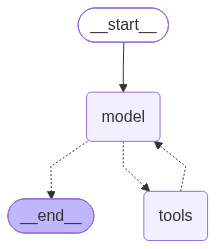

In [20]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 工具重试机制

In [21]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint
load_dotenv(override=True)
flag = 0

@tool(parse_docstring=True)
def get_weather(city:str)->str:
    """
    天气查询工具

    Args:
        city:城市
    """
    global flag
    flag+=1

    if flag < 3:
        # raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}天气不错"

messages = [
    SystemMessage("""
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]
agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})

for msg in response["messages"]:
    msg.pretty_print()

================================ System Message ================================


    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    
================================ Human Message =================================

你好，杭州今天的天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_wxoZXLl6nlQ1SGy9wZkR3139)
 Call ID: call_00_wxoZXLl6nlQ1SGy9wZkR3139
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_V2xsFeLc8bTzWhIH1D4z9175)
 Call ID: call_00_V2xsFeLc8bTzWhIH1D4z9175
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
=======

## agent调用工具原则

 - 依据工具的docstring

AI根据：
1.问题内容
2.每个工具描述
3.自动选择匹配的工具

## agent选错工具

- 原因：多个工具功能相似，工具太多导致混淆


解决：
1.只给必要的工具
2.工具当中明确区分
3.在system_prompt中说明工具场景

## 高级agent


### 1.设置agent名称

创建agent时，LangChain允许用户指定其名称

#### 经典使用场景

1. Multi-Agent
2. 流式输出归因
3. 消息身份标记
4. 调试与trace可读性
5. 组件化封装
6. 前端展示与运行态可观测性
7. 作为稳定的运行时身份标识

In [3]:
from langchain.chat_models import init_chat_model
from langchain.agents import  create_agent
from dotenv import  load_dotenv
import os
from rich import print as rprint

load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek")

agent=create_agent(model=model,
                   name="r-agent")

response=agent.invoke({"messages":["你好"]})

for msg in response["messages"]:
    rprint(msg)

HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='cbea3a74-b9f8-4be5-94ce-ef80ed6c9589')

AIMessage(
    content='你好！很高兴见到你 😊 
有什么我可以帮你的吗？无论是聊天、回答问题、写作、翻译，还是分析资料，我都很乐意帮忙。',
    additional_kwargs={
        'refusal': None,
        'reasoning_content': 'The user just said "你好" (Hello) in Chinese. I should respond in Chinese, warmly and
helpfully, and perhaps ask how I can help.'
    },
    response_metadata={
        'token_usage': {
            'completion_tokens': 65,
            'prompt_tokens': 31,
            'total_tokens': 96,
            'completion_tokens_details': {
                'accepted_prediction_tokens': None,
                'audio_tokens': None,
                'reasoning_tokens': 32,
                'rejected_prediction_tokens': None
            },
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 31
        },
        'model_provider': 'deepseek',
        'model_name': 'deepseek-flash',
        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
        'id': 'bdf77bce-3c3d-41c9-bb21-b88e1a604837',
        'finish_reason': 'stop',
        'logprobs': None
    },
    name='r-agent',
    id='lc_run--01a1d381-7e5f-756f-abde-5cbbd901e270-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 31,
        'output_tokens': 65,
        'total_tokens': 96,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {'reasoning': 32}
    }
)

### 2.系统提示词

使用 create_agent 创建 Agent 时，需传入 模型 和 工具 、可选地传入 系统提示词 。提示词为Agent提供了任务背景、行为准则和操作指南。

系统指令，即SystemMessage，通过 system_prompt 设置，定义 Agent 行为。这个参数可以是 str或者 SystemMessage类型 。

In [ ]:
agent=create_agent(model=model,
                   tools=[get_weather],
                   system_prompt="""
                    你是天气助手。
                    工作流程：
                    1. 理解用户的城市查询
                    2. 使用 get_weather 工具获取数据
                    3. 简洁清晰地回答
                    输出格式：
                    - 天气状况
                    - 温度
                    - 注意事项（如有）
                   """)

In [5]:
from langchain_tavily import TavilySearch
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek")

web_search=TavilySearch(max_results=2)

agent=create_agent(model=model,
                   tools=[web_search],
                   system_prompt="你是一个万能助手")

result=agent.invoke({"messages":[{"role":"user","content":"请查询2026足球世界杯的冠军是？"}]})

print(result["messages"][-1].content)

**2026年世界杯冠军：西班牙** 🇪🇸

**决赛结果：西班牙 1–0 阿根廷（加时赛）**

| 项目 | 信息 |
|---|---|
| 日期 | 2026年7月19日 |
| 地点 | 美国新泽西州东卢瑟福，大都会人寿体育场（MetLife Stadium，赛事期间称"纽约新泽西体育场"） |
| 进球者 | 费兰·托雷斯（Ferran Torres），加时赛绝杀 |
| 决赛最佳球员 | 费兰·托雷斯 |
| 主裁判 | 斯拉夫科·温契奇（斯洛文尼亚） |
| 现场观众 | 80,663人 |

**几个看点：**

- 这是西班牙队史**第二座**世界杯冠军，首座是2010年南非世界杯（决赛同样1–0击败荷兰）。
- 西班牙由此成为**首支在欧洲以外（北美洲）夺得世界杯的欧洲球队**。
- 西班牙同时持有男足和女足世界杯冠军，这是历史首次。
- 阿根廷作为卫冕冠军失利；常规时间内阿根廷 0 射门，是1966年有统计以来世界杯决赛史上首次。阿根廷门将埃米利亚诺·马丁内斯全场11次扑救，创下世界杯决赛扑救纪录。
- 阿根廷中场恩佐·费尔南德斯在常规时间末段两黄变一红被罚下，加时赛阿根廷少打一人。
- 本届是首届扩军至48队的世界杯，由美国、加拿大、墨西哥联合举办，共104场比赛。

信息来源：NPR（2026年7月19日、20日报道）、中文维基百科"2026年国际足协世界杯决赛"条目。


### 3.结构化输出

结构化输出是Agent的核心功能之一，它允许Agent以特定、可预测的格式返回数据，而不是传统的自然语言响应。通过结构化输出，开发者可以直接获得 Pydantic模型 、 JSON对象 或 数据类 等结构化数据，这些数据能够被应用程序直接使用，无需复杂的解析过程。
![image.png](images/structured_output.png)

LangChain的create_agent()函数自动处理结构化输出的全过程。用户只需通过 “response_format”参数 设置期望的输出模式（Schema）。
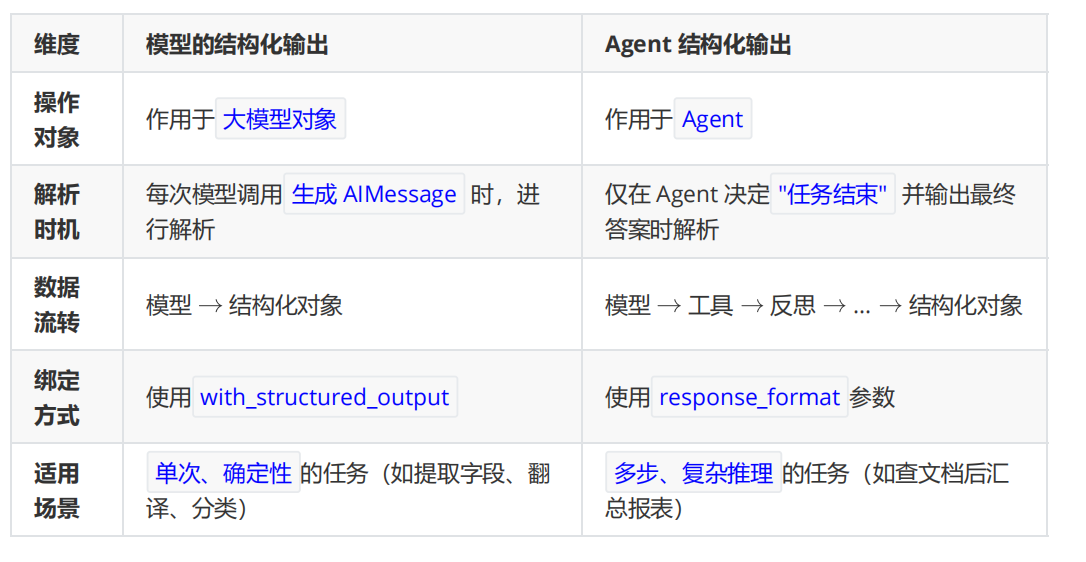

#### 3.1 ProviderStrategy

使用模型提供商的原生结构化输出功能实现结构化输出，适用于支持原生化输出的模型

In [10]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy, ToolStrategy
from langchain.messages import HumanMessage
from rich import print as rprint
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek",
                      )

class ContactInfo(BaseModel):
    name:str=Field(description="用户姓名")
    email:str=Field(description="用户邮箱")
    phone:str=Field(description="用户电话")

agent=create_agent(model=model,
                   response_format=ProviderStrategy(ContactInfo))

response=agent.invoke({"messages":[HumanMessage("从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912")]})

for msg in response["messages"]:
    msg.pretty_print()

BadRequestError: Error code: 400 - {'error': {'message': 'This response_format type is unavailable now (request_id: 3331ce23-6f08-4eed-8fd9-f357bb6f4902)', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_request_error'}}

ProviderStrategy不支持deepseek模型

#### 3.2 ToolStrategy

对于不支持原生结构化输出的模型，LangChain采用“ToolStrategy”工具调用的方式实现结构化输出。

此策略兼容绝大多数 支持工具调用 的现代模型，其核心原理是动态创建一个" 虚拟工具 "，该工具的输入参数对应着期望的数据结构。

当模型需要生成最终答案时，系统会引导模型 "调用"这个虚拟工具 ，从而间接产生符合要求的结构化数据。

In [11]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy,ToolStrategy
from langchain.messages import HumanMessage
from rich import print as rprint
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek",
                      reasoning_effort="none")

class ContactInfo(BaseModel):
    name:str=Field(description="用户姓名")
    email:str=Field(description="用户邮箱")
    phone:str=Field(description="用户电话")

agent=create_agent(model=model,
                   response_format=ToolStrategy(ContactInfo))

response=agent.invoke({"messages":[HumanMessage("从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912")]})

for msg in response["messages"]:
    msg.pretty_print()

================================ Human Message =================================

从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912
================================== Ai Message ==================================
Tool Calls:
  ContactInfo (call_00_9p4mIVehSjisMSeLcf6f2719)
 Call ID: call_00_9p4mIVehSjisMSeLcf6f2719
  Args:
    name: 小明
    email: shkstart@atguigu.com
    phone: 12345678912
================================= Tool Message =================================
Name: ContactInfo

Returning structured response: name='小明' email='shkstart@atguigu.com' phone='12345678912'


#### 3.3 type / AutoStrategy

当我们直接传入一个定义类型时，LangChain会自动包装为AutoStrategy，触发 自动选择策略 ：如果模型支持原生结构化输出（如OpenAI、Anthropic Claude或xAI Grok），则优先使用ProviderStrategy；否则使用ToolStrategy。

In [13]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import AutoStrategy
from langchain.messages import HumanMessage
from rich import print as rprint
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek",
                      reasoning_effort="none")

class ContactInfo(BaseModel):
    name:str=Field(description="用户姓名")
    email:str=Field(description="用户邮箱")
    phone:str=Field(description="用户电话")

agent=create_agent(model=model,
                   response_format=AutoStrategy(ContactInfo))

response=agent.invoke({"messages":[HumanMessage("从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912")]})

print(response["structured_response"])

name='小明' email='shkstart@atguigu.com' phone='12345678912'


#### 3.4 None

默认配置，表示不以结构化输出，以 自然语言 响应用户问题。

## 自定义工具消息：tool_message_content参数

我们可以通过ToolStrategy的 tool_message_content 参数定制其消息内容，将指定的内容写入对话历史的提示信息，这样做的好处如下：

1. 在最终用户可见的对话流中，使用 更自然的消息 替代原始数据。
2. 用简短的确认信息替代可能很长的数据块， 减少token消耗 。

In [15]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import AutoStrategy,ToolStrategy
from langchain.messages import HumanMessage
from rich import print as rprint
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek",
                      reasoning_effort="none")

class ContactInfo(BaseModel):
    name:str=Field(description="用户姓名")
    email:str=Field(description="用户邮箱")
    phone:str=Field(description="用户电话")

agent=create_agent(model=model,
                   response_format=ToolStrategy(ContactInfo,tool_message_content="已成功抽取信息"))

response=agent.invoke({"messages":[HumanMessage("从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912")]})

rprint(response)

{
    'messages': [
        HumanMessage(
            content='从这段话中抽取结构化信息：小明的邮箱地址为：shkstart@atguigu.com，手机号：12345678912',
            additional_kwargs={},
            response_metadata={},
            id='bc2c2871-3998-4b2b-b962-159388156d35'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 74,
                    'prompt_tokens': 336,
                    'total_tokens': 410,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128},
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 208
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '12a1c957-b4fd-4ba2-be70-519a8865d998',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3a2-0075-702f-a4a0-2fe094b9ee65-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '小明', 'email': 'shkstart@atguigu.com', 'phone': '12345678912'},
                    'id': 'call_00_rePmqcsT6DYq1EdKaFME4941',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 336,
                'output_tokens': 74,
                'total_tokens': 410,
                'input_token_details': {'cache_read': 128},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='已成功抽取信息',
            name='ContactInfo',
            id='cb369b8e-442c-478e-800d-d9e01fde031e',
            tool_call_id='call_00_rePmqcsT6DYq1EdKaFME4941'
        )
    ],
    'structured_response': ContactInfo(name='小明', email='shkstart@atguigu.com', phone='12345678912')
}

## 错误处理：handel_errors参数

受限于模型能力，大模型输出的内容可能并 不符合格式要求 ，ToolStrategy通过其 handle_errors参数 提供了结构化过程错误处理策略，以下是主要的几种方式及其用途：
- handle_errors=True： LangChain默认方式 ， 捕获所有异常 ，并使用LangChain 内置的、信息明确的 错误消息模板 提示模型重试，确保最终能得到符合预定格式的有效数据。适用于大多数希望自动处理错误的通用场景。
- handle_errors=False：关闭自动重试机制，任何异常都会 直接抛出 ，会 中断程序 运行。
- handle_errors="自定义字符串"：捕获所有异常，但使用开发者 预设的固定字符串 作为错误消息。适用于需要统一、友好的用户提示，或进行特定业务引导的场景。
- handle_errors=ExceptionType：仅 捕获指定类型(如ValueError) 或元组中的异常类型并进行重试， 其他异常直接抛出 。适用于需要 精准控制 ，只对特定错误进行重试的场景。
- handle_errors=callable：灵活性最高的方式，使用开发者 自定义的函数来处理异常 ，可根据不同的异常类型返回差异化的提示信息。适用于需要复杂、精细化错误处理的场景。

In [16]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from rich import print as rprint
class ContactInfo(BaseModel):
    """个人联系信息"""
    name: str = Field(description="姓名")
    email: str = Field(description="电子邮箱")
class EventDetails(BaseModel):
    """活动详情"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="活动日期")
agent = create_agent(
    model=model,
    response_format=ToolStrategy(
    Union[ContactInfo, EventDetails],
    tool_message_content="提取完成！",
    handle_errors=True
    #handle_errors="请检查输入数据"
    )
)
result = agent.invoke({
    "messages": [{
    "role": "user",
    "content": f"请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：2026-07-15"
    }]
})
rprint(result)
# for msg in result["messages"]:
# msg.pretty_print()
#
# report_data = result["structured_response"]
# print(report_data)

{
    'messages': [
        HumanMessage(
            content='请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：
2026-07-15',
            additional_kwargs={},
            response_metadata={},
            id='078de636-d2b4-47e7-a2b5-367293ce25d7'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 106,
                    'prompt_tokens': 400,
                    'total_tokens': 506,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 400
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': 'de01bd55-3958-427f-8f86-e925ddfbc92c',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3a9-40ba-7422-aff3-ac75e52e9e7f-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_00_dpW33kvDme5PbW5alyae5610',
                    'type': 'tool_call'
                },
                {
                    'name': 'EventDetails',
                    'args': {'event_name': '公司年会', 'date': '2026-07-15'},
                    'id': 'call_01_d7O8SJMK0fCyuzFVdHOQ1769',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 400,
                'output_tokens': 106,
                'total_tokens': 506,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='Error: Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) 
when only one is expected.\n Please fix your mistakes.',
            name='ContactInfo',
            id='0cf9de68-fe41-4ff7-ad63-5cff39b7ad49',
            tool_call_id='call_00_dpW33kvDme5PbW5alyae5610'
        ),
        ToolMessage(
            content='Error: Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) 
when only one is expected.\n Please fix your mistakes.',
            name='EventDetails',
            id='18583335-734c-44b7-bfd0-ac13ff8d9221',
            tool_call_id='call_01_d7O8SJMK0fCyuzFVdHOQ1769'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 55,
                    'prompt_tokens': 581,
                    'total_tokens': 636,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 384},
                    'prompt_cache_hit_tokens': 384,
                    'prompt_cache_miss_tokens': 197
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '5708ad4f-4413-4f90-aef9-40687d4f1b5f',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3a9-44e4-7276-a3dc-ea5b8108bf36-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_00_jlOYGi8WfPlQvresQnpV9033',
                    'type': 'tool_call'
                }
            

 handle_errors改为False

In [17]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from rich import print as rprint
class ContactInfo(BaseModel):
    """个人联系信息"""
    name: str = Field(description="姓名")
    email: str = Field(description="电子邮箱")
class EventDetails(BaseModel):
    """活动详情"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="活动日期")
agent = create_agent(
    model=model,
    response_format=ToolStrategy(
    Union[ContactInfo, EventDetails],
    tool_message_content="提取完成！",
    handle_errors=False
    #handle_errors="请检查输入数据"
    )
)
result = agent.invoke({
    "messages": [{
    "role": "user",
    "content": f"请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：2026-07-15"
    }]
})
rprint(result)
# for msg in result["messages"]:
# msg.pretty_print()
#
# report_data = result["structured_response"]
# print(report_data)

MultipleStructuredOutputsError: Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) when only one is expected.

 handle_errors改为"请检查输入数据"

In [19]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from rich import print as rprint
class ContactInfo(BaseModel):
    """个人联系信息"""
    name: str = Field(description="姓名")
    email: str = Field(description="电子邮箱")
class EventDetails(BaseModel):
    """活动详情"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="活动日期")
agent = create_agent(
    model=model,
    response_format=ToolStrategy(
    Union[ContactInfo, EventDetails],
    tool_message_content="提取完成！",
    handle_errors="请检查输入数据"
    )
)
result = agent.invoke({
    "messages": [{
    "role": "user",
    "content": f"请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：2026-07-15"
    }]
})
rprint(result)
# for msg in result["messages"]:
# msg.pretty_print()
#
# report_data = result["structured_response"]
# print(report_data)

KeyboardInterrupt: 

1. ToolStrategy允许指定多个类型“Union[ContactInfo, EventDetails]”这种写法，但是最终只会转换成一种结构化类型输出。
2. 当ToolStrategy通过“Union[ContactInfo, EventDetails]”指定多个类型时，在内部调用生成结构化类型工具会报错。此时：handle_errors=True（默认值）开始发挥作用，系统会生成一个ToolMessage，明确告诉
LLM“Error: Model incorrectly returned multiple structured responses (ContactInfo,EventDetails) when only one is expected.”，大模型收到这个精准的反馈后，会重新进行推理，最终选择并输出一个最符合要求的Schema。如果handle_errors 设置为False，执行代码过程直接报错。
3. 当格式化输出有错误时，Agent内部会进行工具调用重试，直到符合要求格式化输出前， 可能会进行多次重试 。

### 设定为指定异常类型

1. MultipleStructuredOutputsError

多结构化输出错误，当返回的工具调用请求数量大于1时，抛出该异常，默认情况下LangChain会拦截异常并提醒模型重试。

2. StructuredOutputValidationError

输出结构化验证错误，当输出格式不符合结构化要求时，抛出上述异常。默认情况下LangChain会拦截该异常并自动重试

In [20]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy,MultipleStructuredOutputsError,StructuredOutputValidationError
from rich import print as rprint
class ContactInfo(BaseModel):
    """个人联系信息"""
    name: str = Field(description="姓名")
    email: str = Field(description="电子邮箱")
class EventDetails(BaseModel):
    """活动详情"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="活动日期")
agent = create_agent(
    model=model,
    response_format=ToolStrategy(
    Union[ContactInfo, EventDetails],
    tool_message_content="提取完成！",
    handle_errors=(MultipleStructuredOutputsError,StructuredOutputValidationError)
    )
)
result = agent.invoke({
    "messages": [{
    "role": "user",
    "content": f"请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：2026-07-15"
    }]
})
rprint(result)
# for msg in result["messages"]:
# msg.pretty_print()
#
# report_data = result["structured_response"]
# print(report_data)

{
    'messages': [
        HumanMessage(
            content='请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：
2026-07-15',
            additional_kwargs={},
            response_metadata={},
            id='35f95761-41af-4291-8e05-5c76551a9964'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 106,
                    'prompt_tokens': 400,
                    'total_tokens': 506,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                    'prompt_cache_hit_tokens': 256,
                    'prompt_cache_miss_tokens': 144
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': 'd1c1720f-903a-476a-9ed6-9344f47e146c',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3bc-a10b-7677-8f33-0b7085fd5447-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_00_K5oKeTEb9Uvsxna5yzHH7622',
                    'type': 'tool_call'
                },
                {
                    'name': 'EventDetails',
                    'args': {'event_name': '公司年会', 'date': '2026-07-15'},
                    'id': 'call_01_93d2O2F1kxnwLJnNLR9C6906',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 400,
                'output_tokens': 106,
                'total_tokens': 506,
                'input_token_details': {'cache_read': 256},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='Error: Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) 
when only one is expected.\n Please fix your mistakes.',
            name='ContactInfo',
            id='9bc7c984-ea4b-445f-9cf2-68438766fd5d',
            tool_call_id='call_00_K5oKeTEb9Uvsxna5yzHH7622'
        ),
        ToolMessage(
            content='Error: Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) 
when only one is expected.\n Please fix your mistakes.',
            name='EventDetails',
            id='c87db048-851b-4253-8ce7-af845f3d7945',
            tool_call_id='call_01_93d2O2F1kxnwLJnNLR9C6906'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 55,
                    'prompt_tokens': 581,
                    'total_tokens': 636,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 384},
                    'prompt_cache_hit_tokens': 384,
                    'prompt_cache_miss_tokens': 197
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '6f1e8e47-ba00-4812-b5d3-2cd3fa97cbc9',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3bc-a473-743a-b220-b42617ae13f4-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_00_0Nu0SACCz7gYE8k3ovIb1106',
                    'type': 'tool_call'
                }
      

### 设置为自定义错误处理函数

指定异常处理函数并返回字符串时，LangChain会在遇到异常时自动重试并将异常处理函数的返回值作为ToolMessage的内容。

我们也可以选择在异常处理函数中抛出异常

In [21]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy,MultipleStructuredOutputsError,StructuredOutputValidationError
from rich import print as rprint

def custom_error_handler(error: Exception) -> str:
    """自定义错误处理器"""
    error_str = str(error)
    print(f"捕获到错误类型：{type(error).__name__}")
    print(f"错误详情：{error_str}")
    if isinstance(error, StructuredOutputValidationError):
        return "数据格式有误，请检查字段是否符合要求。"
    elif isinstance(error, MultipleStructuredOutputsError):
        return "检测到多个响应，请选择最相关的一个进行返回。"
    else:
        return f"Error: {error_str}"

class ContactInfo(BaseModel):
    """个人联系信息"""
    name: str = Field(description="姓名")
    email: str = Field(description="电子邮箱")
class EventDetails(BaseModel):
    """活动详情"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="活动日期")
agent = create_agent(
    model=model,
    response_format=ToolStrategy(
    Union[ContactInfo, EventDetails],
    tool_message_content="提取完成！",
    handle_errors=custom_error_handler
    )
)
result = agent.invoke({
    "messages": [{
    "role": "user",
    "content": f"请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：2026-07-15"
    }]
})
rprint(result)
# for msg in result["messages"]:
# msg.pretty_print()
#
# report_data = result["structured_response"]
# print(report_data)

捕获到错误类型：MultipleStructuredOutputsError
错误详情：Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) when only one is expected.


{
    'messages': [
        HumanMessage(
            content='请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：
2026-07-15',
            additional_kwargs={},
            response_metadata={},
            id='5e89b662-8d2f-4706-aa81-3097658915ed'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 106,
                    'prompt_tokens': 400,
                    'total_tokens': 506,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                    'prompt_cache_hit_tokens': 256,
                    'prompt_cache_miss_tokens': 144
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '9bf4ebf2-b22f-4545-b1d2-a5a555735514',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3bf-d0bf-7387-9e9d-c891abd31a4a-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_00_gOzdJw9W9hB8OFHGOwrs5625',
                    'type': 'tool_call'
                },
                {
                    'name': 'EventDetails',
                    'args': {'event_name': '公司年会', 'date': '2026-07-15'},
                    'id': 'call_01_BPFsHOIBE2GosHW6CZZT0852',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 400,
                'output_tokens': 106,
                'total_tokens': 506,
                'input_token_details': {'cache_read': 256},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='检测到多个响应，请选择最相关的一个进行返回。',
            name='ContactInfo',
            id='1a34a5ea-35ab-48d3-a060-797adc9edf94',
            tool_call_id='call_00_gOzdJw9W9hB8OFHGOwrs5625'
        ),
        ToolMessage(
            content='检测到多个响应，请选择最相关的一个进行返回。',
            name='EventDetails',
            id='a9e5fc14-31c3-47ec-ab82-90f9fa3bcb2b',
            tool_call_id='call_01_BPFsHOIBE2GosHW6CZZT0852'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 55,
                    'prompt_tokens': 555,
                    'total_tokens': 610,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 384},
                    'prompt_cache_hit_tokens': 384,
                    'prompt_cache_miss_tokens': 171
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': '2c14493e-ee22-4fe9-9161-a6f6a3be6c20',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3bf-d59f-7030-bd22-e4a3c183ce60-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_00_g4ttwt5YSLOwOWVcJe4c1056',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 555,
                'output_tokens': 55,
                'total_tokens': 610,
                'input_token_details': {'cache_read': 384},
      

### 流式输出及模式

通过流式调用增强用户体验，实时显示agent运行过程中的更新
- 通过“ agent.stream(stream_mode=指定模式) ”来指定。具体模式有：values、updates（默认）、messages、custom、checkpoints、tasks、debug。

In [22]:
# values

from langchain.agents import  create_agent
from langchain.tools import  tool
from typing import Dict,Any
from rich import print as rprint

@tool
def query_customer_data(customer_id: str) -> Dict[str, Any]:
    """
    查询客户基本信息
    Args:
        customer_id: 客户ID，用于唯一标识客户
    returns:
        包含客户基本信息的字典，如姓名、等级、加入日期等
    """
    # 模拟数据库查询
    return {"name": "张三","level": "VIP","join_date": "2023-01-15"}

@tool
def check_order_history(customer_id: str) -> Dict[str, Any]:
    """
    查询客户订单历史
    Args:
        customer_id: 客户ID，用于唯一标识客户
    Returns:
        包含客户订单历史的字典，如总订单数、总花费等
    """
    return {"total_orders": 15,"total_spent": 25800.00}
@tool
def get_current_promotions() -> Dict[str, Any]:
    """
    获取当前可用促销活动
    Returns:
        包含当前可用促销活动的字典，如活动名称、有效日期等
    """
    return {
        "promotions": ["老用户优惠", "会员专属折扣"],
        "valid_until": "2027-01-31"
    }

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions]
)

for chunk in customer_service_agent.stream(
    {"messages": [{"role": "user","content": "查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"}]},
    stream_mode="values"
):
    rprint(chunk)
    print("-" * 50)

{
    'messages': [
        HumanMessage(
            content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
            additional_kwargs={},
            response_metadata={},
            id='351b0255-760e-413a-96e6-a432d7a2da75'
        )
    ]
}

--------------------------------------------------


{
    'messages': [
        HumanMessage(
            content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
            additional_kwargs={},
            response_metadata={},
            id='351b0255-760e-413a-96e6-a432d7a2da75'
        ),
        AIMessage(
            content='我会为您并行查询该客户的个人信息、历史订单和当前可用优惠。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 105,
                    'prompt_tokens': 453,
                    'total_tokens': 558,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 453
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': 'dc62fd69-1a4b-4668-8f23-1b4c45870919',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3c5-fb5e-7537-9739-c9c3df2e6139-0',
            tool_calls=[
                {
                    'name': 'query_customer_data',
                    'args': {'customer_id': 'CUST123456'},
                    'id': 'call_00_7ozQAT3dXXCEqkYMIwIz6015',
                    'type': 'tool_call'
                },
                {
                    'name': 'check_order_history',
                    'args': {'customer_id': 'CUST123456'},
                    'id': 'call_01_0CWoAd4MOUBFXijUCALd8105',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_current_promotions',
                    'args': {},
                    'id': 'call_02_2DJ3j0hzBs6YIu74lfvv8702',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 453,
                'output_tokens': 105,
                'total_tokens': 558,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        )
    ]
}

--------------------------------------------------


{
    'messages': [
        HumanMessage(
            content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
            additional_kwargs={},
            response_metadata={},
            id='351b0255-760e-413a-96e6-a432d7a2da75'
        ),
        AIMessage(
            content='我会为您并行查询该客户的个人信息、历史订单和当前可用优惠。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 105,
                    'prompt_tokens': 453,
                    'total_tokens': 558,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 453
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': 'dc62fd69-1a4b-4668-8f23-1b4c45870919',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3c5-fb5e-7537-9739-c9c3df2e6139-0',
            tool_calls=[
                {
                    'name': 'query_customer_data',
                    'args': {'customer_id': 'CUST123456'},
                    'id': 'call_00_7ozQAT3dXXCEqkYMIwIz6015',
                    'type': 'tool_call'
                },
                {
                    'name': 'check_order_history',
                    'args': {'customer_id': 'CUST123456'},
                    'id': 'call_01_0CWoAd4MOUBFXijUCALd8105',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_current_promotions',
                    'args': {},
                    'id': 'call_02_2DJ3j0hzBs6YIu74lfvv8702',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 453,
                'output_tokens': 105,
                'total_tokens': 558,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='{"name": "张三", "level": "VIP", "join_date": "2023-01-15"}',
            name='query_customer_data',
            id='fc939712-5c9d-4ea7-ae56-1f001c9549cb',
            tool_call_id='call_00_7ozQAT3dXXCEqkYMIwIz6015'
        ),
        ToolMessage(
            content='{"total_orders": 15, "total_spent": 25800.0}',
            name='check_order_history',
            id='dc6e3350-2403-4ce6-aebe-a337496dcb88',
            tool_call_id='call_01_0CWoAd4MOUBFXijUCALd8105'
        ),
        ToolMessage(
            content='{"promotions": ["老用户优惠", "会员专属折扣"], "valid_until": "2027-01-31"}',
            name='get_current_promotions',
            id='d30d3935-ca1d-41f2-bd5c-214cc94d6016',
            tool_call_id='call_02_2DJ3j0hzBs6YIu74lfvv8702'
        )
    ]
}

--------------------------------------------------


{
    'messages': [
        HumanMessage(
            content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
            additional_kwargs={},
            response_metadata={},
            id='351b0255-760e-413a-96e6-a432d7a2da75'
        ),
        AIMessage(
            content='我会为您并行查询该客户的个人信息、历史订单和当前可用优惠。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 105,
                    'prompt_tokens': 453,
                    'total_tokens': 558,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 453
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                'id': 'dc62fd69-1a4b-4668-8f23-1b4c45870919',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1d3c5-fb5e-7537-9739-c9c3df2e6139-0',
            tool_calls=[
                {
                    'name': 'query_customer_data',
                    'args': {'customer_id': 'CUST123456'},
                    'id': 'call_00_7ozQAT3dXXCEqkYMIwIz6015',
                    'type': 'tool_call'
                },
                {
                    'name': 'check_order_history',
                    'args': {'customer_id': 'CUST123456'},
                    'id': 'call_01_0CWoAd4MOUBFXijUCALd8105',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_current_promotions',
                    'args': {},
                    'id': 'call_02_2DJ3j0hzBs6YIu74lfvv8702',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 453,
                'output_tokens': 105,
                'total_tokens': 558,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='{"name": "张三", "level": "VIP", "join_date": "2023-01-15"}',
            name='query_customer_data',
            id='fc939712-5c9d-4ea7-ae56-1f001c9549cb',
            tool_call_id='call_00_7ozQAT3dXXCEqkYMIwIz6015'
        ),
        ToolMessage(
            content='{"total_orders": 15, "total_spent": 25800.0}',
            name='check_order_history',
            id='dc6e3350-2403-4ce6-aebe-a337496dcb88',
            tool_call_id='call_01_0CWoAd4MOUBFXijUCALd8105'
        ),
        ToolMessage(
            content='{"promotions": ["老用户优惠", "会员专属折扣"], "valid_until": "2027-01-31"}',
            name='get_current_promotions',
            id='d30d3935-ca1d-41f2-bd5c-214cc94d6016',
            tool_call_id='call_02_2DJ3j0hzBs6YIu74lfvv8702'
        ),
        AIMessage(
            content='已为您查询到客户 CUST123456 的信息，汇总如下：\n\n## 👤 个人信息\n| 项目 | 内容 
|\n|---|---|\n| 姓名 | 张三 |\n| 会员等级 | VIP |\n| 加入日期 | 2023-01-15 |\n\n## 📦 历史订单\n| 项目 | 数值 
|\n|---|---|\n| 总订单数 | 15 笔 |\n| 累计消费 | ¥25,800.00 |\n\n平均每单约 
¥1,720，属于消费能力较强的高价值客户。\n\n## 🎁 当前可用优惠\n- 老用户优惠\n- 会员专属折扣\n- 
**有效期至：2027-01-31**\n\n**小结：** 该客户为 VIP 老客户，累计消费 
¥25,800，可享受「老用户优惠」与「会员专属折扣」两项活动（均有效至 
2027-01-31）。如需进一步分析（如消费趋势、推荐优惠组合等），请告诉我。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 209,
                    'prompt_tokens': 655,
                    'total_tokens': 864,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 512},
                    'prompt_cache_hit_tokens': 512,
                    'prompt_cache_miss_tokens': 143

--------------------------------------------------


In [23]:
# values

from langchain.agents import  create_agent
from langchain.tools import  tool
from typing import Dict,Any
from rich import print as rprint

@tool
def query_customer_data(customer_id: str) -> Dict[str, Any]:
    """
    查询客户基本信息
    Args:
        customer_id: 客户ID，用于唯一标识客户
    returns:
        包含客户基本信息的字典，如姓名、等级、加入日期等
    """
    # 模拟数据库查询
    return {"name": "张三","level": "VIP","join_date": "2023-01-15"}

@tool
def check_order_history(customer_id: str) -> Dict[str, Any]:
    """
    查询客户订单历史
    Args:
        customer_id: 客户ID，用于唯一标识客户
    Returns:
        包含客户订单历史的字典，如总订单数、总花费等
    """
    return {"total_orders": 15,"total_spent": 25800.00}
@tool
def get_current_promotions() -> Dict[str, Any]:
    """
    获取当前可用促销活动
    Returns:
        包含当前可用促销活动的字典，如活动名称、有效日期等
    """
    return {
        "promotions": ["老用户优惠", "会员专属折扣"],
        "valid_until": "2027-01-31"
    }

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions]
)

for chunk in customer_service_agent.stream(
    {"messages": [{"role": "user","content": "查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"}]},
    stream_mode="updates"
):
    rprint(chunk)
    print("-" * 50)

{
    'model': {
        'messages': [
            AIMessage(
                content='我会为您查询客户 CUST123456 的详细信息、订单历史和当前可用促销活动。',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 109,
                        'prompt_tokens': 453,
                        'total_tokens': 562,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                        'prompt_cache_hit_tokens': 256,
                        'prompt_cache_miss_tokens': 197
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
                    'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                    'id': '29cdcc66-f4c9-4778-a790-0be02d902755',
                    'finish_reason': 'tool_calls',
                    'logprobs': None
                },
                id='lc_run--01a1d3c7-11a1-74c6-986b-dbb73273b1c1-0',
                tool_calls=[
                    {
                        'name': 'query_customer_data',
                        'args': {'customer_id': 'CUST123456'},
                        'id': 'call_00_wiEMLN60bQjM3TD291Pb1611',
                        'type': 'tool_call'
                    },
                    {
                        'name': 'check_order_history',
                        'args': {'customer_id': 'CUST123456'},
                        'id': 'call_01_JtXPudxTQiRkXgnKxBd93070',
                        'type': 'tool_call'
                    },
                    {
                        'name': 'get_current_promotions',
                        'args': {},
                        'id': 'call_02_ppPE8rYy5a8Wvh4A6AEM3044',
                        'type': 'tool_call'
                    }
                ],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 453,
                    'output_tokens': 109,
                    'total_tokens': 562,
                    'input_token_details': {'cache_read': 256},
                    'output_token_details': {}
                }
            )
        ]
    }
}

--------------------------------------------------


{
    'tools': {
        'messages': [
            ToolMessage(
                content='{"total_orders": 15, "total_spent": 25800.0}',
                name='check_order_history',
                id='d0c12c3e-b4a2-49c0-94b4-4e7895e8b161',
                tool_call_id='call_01_JtXPudxTQiRkXgnKxBd93070'
            )
        ]
    }
}

--------------------------------------------------


{
    'tools': {
        'messages': [
            ToolMessage(
                content='{"name": "张三", "level": "VIP", "join_date": "2023-01-15"}',
                name='query_customer_data',
                id='87fc7d51-740f-4411-8cbc-cd0ca0da1ef4',
                tool_call_id='call_00_wiEMLN60bQjM3TD291Pb1611'
            )
        ]
    }
}

--------------------------------------------------


{
    'tools': {
        'messages': [
            ToolMessage(
                content='{"promotions": ["老用户优惠", "会员专属折扣"], "valid_until": "2027-01-31"}',
                name='get_current_promotions',
                id='bc5e5a57-6eda-4dd0-87ec-9c86ac2a876f',
                tool_call_id='call_02_ppPE8rYy5a8Wvh4A6AEM3044'
            )
        ]
    }
}

--------------------------------------------------


{
    'model': {
        'messages': [
            AIMessage(
                content='已为您查询到客户 CUST123456 的相关信息，汇总如下：\n\n## 👤 个人信息\n| 项目 | 内容 
|\n|------|------|\n| 姓名 | 张三 |\n| 等级 | VIP |\n| 加入日期 | 2023-01-15 |\n\n## 📦 历史订单\n- 
**总订单数**：15 单\n- **累计消费**：¥25,800.00\n- **客单价**：约 ¥1,720.00\n\n## 🎁 当前可用优惠\n- 老用户优惠\n- 
会员专属折扣\n- **有效期至**：2027-01-31\n\n**小结**：张三是一位 VIP 会员，加入至今已累计消费 2.58 
万元，属于高价值客户，目前可享受「老用户优惠」和「会员专属折扣」两项优惠，均有效至 2027 
年初。\n\n如需进一步分析（如消费趋势、优惠适配建议等），请告诉我。',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 208,
                        'prompt_tokens': 659,
                        'total_tokens': 867,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 512},
                        'prompt_cache_hit_tokens': 512,
                        'prompt_cache_miss_tokens': 147
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
                    'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                    'id': 'bf65a214-eb52-414f-9944-531df60dc997',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a1d3c7-15d0-7432-99e0-8a394979da85-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 659,
                    'output_tokens': 208,
                    'total_tokens': 867,
                    'input_token_details': {'cache_read': 512},
                    'output_token_details': {}
                }
            )
        ]
    }
}

--------------------------------------------------


In [24]:
# values

from langchain.agents import  create_agent
from langchain.tools import  tool
from typing import Dict,Any
from rich import print as rprint

@tool
def query_customer_data(customer_id: str) -> Dict[str, Any]:
    """
    查询客户基本信息
    Args:
        customer_id: 客户ID，用于唯一标识客户
    returns:
        包含客户基本信息的字典，如姓名、等级、加入日期等
    """
    # 模拟数据库查询
    return {"name": "张三","level": "VIP","join_date": "2023-01-15"}

@tool
def check_order_history(customer_id: str) -> Dict[str, Any]:
    """
    查询客户订单历史
    Args:
        customer_id: 客户ID，用于唯一标识客户
    Returns:
        包含客户订单历史的字典，如总订单数、总花费等
    """
    return {"total_orders": 15,"total_spent": 25800.00}
@tool
def get_current_promotions() -> Dict[str, Any]:
    """
    获取当前可用促销活动
    Returns:
        包含当前可用促销活动的字典，如活动名称、有效日期等
    """
    return {
        "promotions": ["老用户优惠", "会员专属折扣"],
        "valid_until": "2027-01-31"
    }

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions]
)

for chunk in customer_service_agent.stream(
    {"messages": [{"role": "user","content": "查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"}]},
    stream_mode="messages"
):
    rprint(chunk)
    print("-" * 50)

(
    AIMessageChunk(
        content='',
        additional_kwargs={},
        response_metadata={'model_provider': 'deepseek'},
        id='lc_run--01a1d3c7-b1fa-7620-b7ba-d10e79543767',
        tool_calls=[],
        invalid_tool_calls=[],
        tool_call_chunks=[]
    ),
    {
        'langgraph_step': 1,
        'langgraph_node': 'model',
        'langgraph_triggers': ('branch:to:model',),
        'langgraph_path': ('__pregel_pull', 'model'),
        'langgraph_checkpoint_ns': 'model:03174b4e-0bb1-4d5f-b53a-5111cdbc39cb',
        'checkpoint_ns': 'model:03174b4e-0bb1-4d5f-b53a-5111cdbc39cb',
        'ls_provider': 'deepseek',
        'ls_model_name': 'deepseek-flash',
        'ls_model_type': 'chat',
        'ls_temperature': None
    }
)

--------------------------------------------------


(
    AIMessageChunk(
        content='I',
        additional_kwargs={},
        response_metadata={'model_provider': 'deepseek'},
        id='lc_run--01a1d3c7-b1fa-7620-b7ba-d10e79543767',
        tool_calls=[],
        invalid_tool_calls=[],
        tool_call_chunks=[]
    ),
    {
        'langgraph_step': 1,
        'langgraph_node': 'model',
        'langgraph_triggers': ('branch:to:model',),
        'langgraph_path': ('__pregel_pull', 'model'),
        'langgraph_checkpoint_ns': 'model:03174b4e-0bb1-4d5f-b53a-5111cdbc39cb',
        'checkpoint_ns': 'model:03174b4e-0bb1-4d5f-b53a-5111cdbc39cb',
        'ls_provider': 'deepseek',
        'ls_model_name': 'deepseek-flash',
        'ls_model_type': 'chat',
        'ls_temperature': None
    }
)

--------------------------------------------------


(
    AIMessageChunk(
        content="'ll",
        additional_kwargs={},
        response_metadata={'model_provider': 'deepseek'},
        id='lc_run--01a1d3c7-b1fa-7620-b7ba-d10e79543767',
        tool_calls=[],
        invalid_tool_calls=[],
        tool_call_chunks=[]
    ),
    {
        'langgraph_step': 1,
        'langgraph_node': 'model',
        'langgraph_triggers': ('branch:to:model',),
        'langgraph_path': ('__pregel_pull', 'model'),
        'langgraph_checkpoint_ns': 'model:03174b4e-0bb1-4d5f-b53a-5111cdbc39cb',
        'checkpoint_ns': 'model:03174b4e-0bb1-4d5f-b53a-5111cdbc39cb',
        'ls_provider': 'deepseek',
        'ls_model_name': 'deepseek-flash',
        'ls_model_type': 'chat',
        'ls_temperature': None
    }
)

--------------------------------------------------


... (518 outputs left out)

(
    AIMessageChunk(
        content='',
        additional_kwargs={},
        response_metadata={
            'finish_reason': 'stop',
            'model_name': 'deepseek-flash',
            'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
            'model_provider': 'deepseek'
        },
        id='lc_run--01a1d3c7-b61e-7186-bb4b-a9aa93fe929f',
        tool_calls=[],
        invalid_tool_calls=[],
        usage_metadata={
            'input_tokens': 660,
            'output_tokens': 214,
            'total_tokens': 874,
            'input_token_details': {'cache_read': 512},
            'output_token_details': {}
        },
        tool_call_chunks=[]
    ),
    {
        'langgraph_step': 3,
        'langgraph_node': 'model',
        'langgraph_triggers': ('branch:to:model',),
        'langgraph_path': ('__pregel_pull', 'model'),
        'langgraph_checkpoint_ns': 'model:2ac71f8f-aeeb-871e-d636-0c4afd5a785b',
        'checkpoint_ns': 'model:2ac71f8f-aeeb-871e-d636-0c4afd5a785b',
        'ls_provider': 'deepseek',
        'ls_model_name': 'deepseek-flash',
        'ls_model_type': 'chat',
        'ls_temperature': None,
        'usage_metadata': {
            'input_tokens': 660,
            'output_tokens': 214,
            'total_tokens': 874,
            'input_token_details': {'cache_read': 512},
            'output_token_details': {}
        },
        'LANGSMITH_TRACING': 'true',
        'LANGSMITH_ENDPOINT': 'https://api.smith.LangChain.com',
        'LANGSMITH_PROJECT': 'study-Lang',
        'revision_id': '68e6b8c-dirty'
    }
)

--------------------------------------------------


(
    AIMessageChunk(
        content='',
        additional_kwargs={},
        response_metadata={},
        id='lc_run--01a1d3c7-b61e-7186-bb4b-a9aa93fe929f',
        tool_calls=[],
        invalid_tool_calls=[],
        tool_call_chunks=[],
        chunk_position='last'
    ),
    {
        'langgraph_step': 3,
        'langgraph_node': 'model',
        'langgraph_triggers': ('branch:to:model',),
        'langgraph_path': ('__pregel_pull', 'model'),
        'langgraph_checkpoint_ns': 'model:2ac71f8f-aeeb-871e-d636-0c4afd5a785b',
        'checkpoint_ns': 'model:2ac71f8f-aeeb-871e-d636-0c4afd5a785b',
        'ls_provider': 'deepseek',
        'ls_model_name': 'deepseek-flash',
        'ls_model_type': 'chat',
        'ls_temperature': None,
        'usage_metadata': {
            'input_tokens': 660,
            'output_tokens': 214,
            'total_tokens': 874,
            'input_token_details': {'cache_read': 512},
            'output_token_details': {}
        },
        'LANGSMITH_TRACING': 'true',
        'LANGSMITH_ENDPOINT': 'https://api.smith.LangChain.com',
        'LANGSMITH_PROJECT': 'study-Lang',
        'revision_id': '68e6b8c-dirty'
    }
)

--------------------------------------------------


In [25]:
# values

from langchain.agents import  create_agent
from langchain.tools import  tool
from typing import Dict,Any
from rich import print as rprint

@tool
def query_customer_data(customer_id: str) -> Dict[str, Any]:
    """
    查询客户基本信息
    Args:
        customer_id: 客户ID，用于唯一标识客户
    returns:
        包含客户基本信息的字典，如姓名、等级、加入日期等
    """
    # 模拟数据库查询
    return {"name": "张三","level": "VIP","join_date": "2023-01-15"}

@tool
def check_order_history(customer_id: str) -> Dict[str, Any]:
    """
    查询客户订单历史
    Args:
        customer_id: 客户ID，用于唯一标识客户
    Returns:
        包含客户订单历史的字典，如总订单数、总花费等
    """
    return {"total_orders": 15,"total_spent": 25800.00}
@tool
def get_current_promotions() -> Dict[str, Any]:
    """
    获取当前可用促销活动
    Returns:
        包含当前可用促销活动的字典，如活动名称、有效日期等
    """
    return {
        "promotions": ["老用户优惠", "会员专属折扣"],
        "valid_until": "2027-01-31"
    }

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions]
)

for chunk in customer_service_agent.stream(
    {"messages": [{"role": "user","content": "查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"}]},
    stream_mode="tasks"
):
    rprint(chunk)
    print("-" * 50)

{
    'id': 'a584fc2d-19a2-0285-666e-42cca3b08c32',
    'name': 'model',
    'input': {
        'messages': [
            HumanMessage(
                content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
                additional_kwargs={},
                response_metadata={},
                id='4130923c-63d2-4053-973a-45735325faa2'
            )
        ]
    },
    'triggers': ('branch:to:model',)
}

--------------------------------------------------


{
    'id': 'a584fc2d-19a2-0285-666e-42cca3b08c32',
    'name': 'model',
    'error': None,
    'result': {
        'messages': [
            AIMessage(
                content="I'll query all three pieces of information for customer CUST123456 for you.",
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 107,
                        'prompt_tokens': 453,
                        'total_tokens': 560,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                        'prompt_cache_hit_tokens': 256,
                        'prompt_cache_miss_tokens': 197
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
                    'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                    'id': '375508e3-0ae0-4db4-a280-08e4afab7ecc',
                    'finish_reason': 'tool_calls',
                    'logprobs': None
                },
                id='lc_run--01a1d3c9-5345-732c-b244-7bf984c0d752-0',
                tool_calls=[
                    {
                        'name': 'query_customer_data',
                        'args': {'customer_id': 'CUST123456'},
                        'id': 'call_00_zaVqSWw8jRPe8PxRJ0l52065',
                        'type': 'tool_call'
                    },
                    {
                        'name': 'check_order_history',
                        'args': {'customer_id': 'CUST123456'},
                        'id': 'call_01_9WI74dFhURtmefUUWNBo3657',
                        'type': 'tool_call'
                    },
                    {
                        'name': 'get_current_promotions',
                        'args': {},
                        'id': 'call_02_5Ay2m3sHRzmtm0NRarZe1499',
                        'type': 'tool_call'
                    }
                ],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 453,
                    'output_tokens': 107,
                    'total_tokens': 560,
                    'input_token_details': {'cache_read': 256},
                    'output_token_details': {}
                }
            )
        ]
    },
    'interrupts': []
}

--------------------------------------------------


{
    'id': '124eff97-2821-ed33-8ee0-544d08a4e14f',
    'name': 'tools',
    'input': {
        '__type': 'tool_call_with_context',
        'tool_call': {
            'name': 'query_customer_data',
            'args': {'customer_id': 'CUST123456'},
            'id': 'call_00_zaVqSWw8jRPe8PxRJ0l52065',
            'type': 'tool_call'
        },
        'state': {
            'messages': [
                HumanMessage(
                    content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
                    additional_kwargs={},
                    response_metadata={},
                    id='4130923c-63d2-4053-973a-45735325faa2'
                ),
                AIMessage(
                    content="I'll query all three pieces of information for customer CUST123456 for you.",
                    additional_kwargs={'refusal': None},
                    response_metadata={
                        'token_usage': {
                            'completion_tokens': 107,
                            'prompt_tokens': 453,
                            'total_tokens': 560,
                            'completion_tokens_details': None,
                            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                            'prompt_cache_hit_tokens': 256,
                            'prompt_cache_miss_tokens': 197
                        },
                        'model_provider': 'deepseek',
                        'model_name': 'deepseek-flash',
                        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                        'id': '375508e3-0ae0-4db4-a280-08e4afab7ecc',
                        'finish_reason': 'tool_calls',
                        'logprobs': None
                    },
                    id='lc_run--01a1d3c9-5345-732c-b244-7bf984c0d752-0',
                    tool_calls=[
                        {
                            'name': 'query_customer_data',
                            'args': {'customer_id': 'CUST123456'},
                            'id': 'call_00_zaVqSWw8jRPe8PxRJ0l52065',
                            'type': 'tool_call'
                        },
                        {
                            'name': 'check_order_history',
                            'args': {'customer_id': 'CUST123456'},
                            'id': 'call_01_9WI74dFhURtmefUUWNBo3657',
                            'type': 'tool_call'
                        },
                        {
                            'name': 'get_current_promotions',
                            'args': {},
                            'id': 'call_02_5Ay2m3sHRzmtm0NRarZe1499',
                            'type': 'tool_call'
                        }
                    ],
                    invalid_tool_calls=[],
                    usage_metadata={
                        'input_tokens': 453,
                        'output_tokens': 107,
                        'total_tokens': 560,
                        'input_token_details': {'cache_read': 256},
                        'output_token_details': {}
                    }
                )
            ]
        }
    },
    'triggers': ('__pregel_push',)
}

--------------------------------------------------


... (10 outputs left out)

{
    'id': '88ba687d-35d0-4bb6-45f4-6cae3546b194',
    'name': 'model',
    'input': {
        'messages': [
            HumanMessage(
                content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
                additional_kwargs={},
                response_metadata={},
                id='4130923c-63d2-4053-973a-45735325faa2'
            ),
            AIMessage(
                content="I'll query all three pieces of information for customer CUST123456 for you.",
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 107,
                        'prompt_tokens': 453,
                        'total_tokens': 560,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                        'prompt_cache_hit_tokens': 256,
                        'prompt_cache_miss_tokens': 197
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
                    'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                    'id': '375508e3-0ae0-4db4-a280-08e4afab7ecc',
                    'finish_reason': 'tool_calls',
                    'logprobs': None
                },
                id='lc_run--01a1d3c9-5345-732c-b244-7bf984c0d752-0',
                tool_calls=[
                    {
                        'name': 'query_customer_data',
                        'args': {'customer_id': 'CUST123456'},
                        'id': 'call_00_zaVqSWw8jRPe8PxRJ0l52065',
                        'type': 'tool_call'
                    },
                    {
                        'name': 'check_order_history',
                        'args': {'customer_id': 'CUST123456'},
                        'id': 'call_01_9WI74dFhURtmefUUWNBo3657',
                        'type': 'tool_call'
                    },
                    {
                        'name': 'get_current_promotions',
                        'args': {},
                        'id': 'call_02_5Ay2m3sHRzmtm0NRarZe1499',
                        'type': 'tool_call'
                    }
                ],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 453,
                    'output_tokens': 107,
                    'total_tokens': 560,
                    'input_token_details': {'cache_read': 256},
                    'output_token_details': {}
                }
            ),
            ToolMessage(
                content='{"name": "张三", "level": "VIP", "join_date": "2023-01-15"}',
                name='query_customer_data',
                id='56e90878-b748-4f30-86dd-1c05d25af3c2',
                tool_call_id='call_00_zaVqSWw8jRPe8PxRJ0l52065'
            ),
            ToolMessage(
                content='{"total_orders": 15, "total_spent": 25800.0}',
                name='check_order_history',
                id='7463fe0a-049b-4a17-8406-fd8a906254a9',
                tool_call_id='call_01_9WI74dFhURtmefUUWNBo3657'
            ),
            ToolMessage(
                content='{"promotions": ["老用户优惠", "会员专属折扣"], "valid_until": "2027-01-31"}',
                name='get_current_promotions',
                id='461a9ce8-b748-4e6f-ad2f-99c235541721',
                tool_call_id='call_02_5Ay2m3sHRzmtm0NRarZe1499'
            )
        ]
    },
    'triggers': ('branch:to:model',)
}

--------------------------------------------------


{
    'id': '88ba687d-35d0-4bb6-45f4-6cae3546b194',
    'name': 'model',
    'error': None,
    'result': {
        'messages': [
            AIMessage(
                content='已为您查询到客户 CUST123456 的信息：\n\n## 👤 个人信息\n- **姓名**：张三\n- 
**会员等级**：VIP\n- **加入日期**：2023-01-15\n\n## 📦 历史订单\n- **总订单数**：15 单\n- 
**累计消费**：¥25,800.00\n- **平均客单价**：约 ¥1,720.00\n\n## 🎁 可用优惠\n- **老用户优惠**\n- **会员专属折扣**\n-
**有效期至**：2027-01-31\n\n该客户是加入两年的 VIP 
会员，消费记录良好，目前有两项优惠可享受。需要我进一步协助分析或推荐适合的促销方案吗？',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 158,
                        'prompt_tokens': 657,
                        'total_tokens': 815,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 512},
                        'prompt_cache_hit_tokens': 512,
                        'prompt_cache_miss_tokens': 145
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
                    'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                    'id': 'f49badee-eb53-4e28-89ad-0d43b9bad846',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a1d3c9-58c9-77b8-aa84-069b7248cf15-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 657,
                    'output_tokens': 158,
                    'total_tokens': 815,
                    'input_token_details': {'cache_read': 512},
                    'output_token_details': {}
                }
            )
        ]
    },
    'interrupts': []
}

--------------------------------------------------


In [26]:
# values

from langchain.agents import  create_agent
from langchain.tools import  tool
from typing import Dict,Any
from rich import print as rprint

@tool
def query_customer_data(customer_id: str) -> Dict[str, Any]:
    """
    查询客户基本信息
    Args:
        customer_id: 客户ID，用于唯一标识客户
    returns:
        包含客户基本信息的字典，如姓名、等级、加入日期等
    """
    # 模拟数据库查询
    return {"name": "张三","level": "VIP","join_date": "2023-01-15"}

@tool
def check_order_history(customer_id: str) -> Dict[str, Any]:
    """
    查询客户订单历史
    Args:
        customer_id: 客户ID，用于唯一标识客户
    Returns:
        包含客户订单历史的字典，如总订单数、总花费等
    """
    return {"total_orders": 15,"total_spent": 25800.00}
@tool
def get_current_promotions() -> Dict[str, Any]:
    """
    获取当前可用促销活动
    Returns:
        包含当前可用促销活动的字典，如活动名称、有效日期等
    """
    return {
        "promotions": ["老用户优惠", "会员专属折扣"],
        "valid_until": "2027-01-31"
    }

customer_service_agent = create_agent(
    model=model,
    tools=[query_customer_data, check_order_history, get_current_promotions]
)

for chunk in customer_service_agent.stream(
    {"messages": [{"role": "user","content": "查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠"}]},
    stream_mode="debug"
):
    rprint(chunk)
    print("-" * 50)

{
    'step': 1,
    'timestamp': '2026-11-13T07:23:40.047447+00:00',
    'type': 'task',
    'payload': {
        'id': '53acb464-8483-70c3-7130-5e9a41424681',
        'name': 'model',
        'input': {
            'messages': [
                HumanMessage(
                    content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
                    additional_kwargs={},
                    response_metadata={},
                    id='1a6f77a9-e23f-4985-bc75-1232b22a3b95'
                )
            ]
        },
        'triggers': ('branch:to:model',)
    }
}

--------------------------------------------------


{
    'step': 1,
    'timestamp': '2026-11-13T07:23:41.031444+00:00',
    'type': 'task_result',
    'payload': {
        'id': '53acb464-8483-70c3-7130-5e9a41424681',
        'name': 'model',
        'error': None,
        'result': {
            'messages': [
                AIMessage(
                    content='我来为您查询客户 CUST123456 的相关信息。',
                    additional_kwargs={'refusal': None},
                    response_metadata={
                        'token_usage': {
                            'completion_tokens': 102,
                            'prompt_tokens': 453,
                            'total_tokens': 555,
                            'completion_tokens_details': None,
                            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                            'prompt_cache_hit_tokens': 256,
                            'prompt_cache_miss_tokens': 197
                        },
                        'model_provider': 'deepseek',
                        'model_name': 'deepseek-flash',
                        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                        'id': 'd89e3915-b254-4b5b-97b0-6618c6f0a1f9',
                        'finish_reason': 'tool_calls',
                        'logprobs': None
                    },
                    id='lc_run--01a1d3ca-689c-77f1-b50e-760331cc19a8-0',
                    tool_calls=[
                        {
                            'name': 'query_customer_data',
                            'args': {'customer_id': 'CUST123456'},
                            'id': 'call_00_d7NUtQ2Aj5jr31dQOo8g1876',
                            'type': 'tool_call'
                        },
                        {
                            'name': 'check_order_history',
                            'args': {'customer_id': 'CUST123456'},
                            'id': 'call_01_Rab83300gApPqS7Psa4p3737',
                            'type': 'tool_call'
                        },
                        {
                            'name': 'get_current_promotions',
                            'args': {},
                            'id': 'call_02_tyyv8I2EEk81sf2B1v0L9837',
                            'type': 'tool_call'
                        }
                    ],
                    invalid_tool_calls=[],
                    usage_metadata={
                        'input_tokens': 453,
                        'output_tokens': 102,
                        'total_tokens': 555,
                        'input_token_details': {'cache_read': 256},
                        'output_token_details': {}
                    }
                )
            ]
        },
        'interrupts': []
    }
}

--------------------------------------------------


{
    'step': 2,
    'timestamp': '2026-11-13T07:23:41.031941+00:00',
    'type': 'task',
    'payload': {
        'id': '6a02f423-9db5-f828-45f6-180aed75fa62',
        'name': 'tools',
        'input': {
            '__type': 'tool_call_with_context',
            'tool_call': {
                'name': 'query_customer_data',
                'args': {'customer_id': 'CUST123456'},
                'id': 'call_00_d7NUtQ2Aj5jr31dQOo8g1876',
                'type': 'tool_call'
            },
            'state': {
                'messages': [
                    HumanMessage(
                        content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
                        additional_kwargs={},
                        response_metadata={},
                        id='1a6f77a9-e23f-4985-bc75-1232b22a3b95'
                    ),
                    AIMessage(
                        content='我来为您查询客户 CUST123456 的相关信息。',
                        additional_kwargs={'refusal': None},
                        response_metadata={
                            'token_usage': {
                                'completion_tokens': 102,
                                'prompt_tokens': 453,
                                'total_tokens': 555,
                                'completion_tokens_details': None,
                                'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                                'prompt_cache_hit_tokens': 256,
                                'prompt_cache_miss_tokens': 197
                            },
                            'model_provider': 'deepseek',
                            'model_name': 'deepseek-flash',
                            'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                            'id': 'd89e3915-b254-4b5b-97b0-6618c6f0a1f9',
                            'finish_reason': 'tool_calls',
                            'logprobs': None
                        },
                        id='lc_run--01a1d3ca-689c-77f1-b50e-760331cc19a8-0',
                        tool_calls=[
                            {
                                'name': 'query_customer_data',
                                'args': {'customer_id': 'CUST123456'},
                                'id': 'call_00_d7NUtQ2Aj5jr31dQOo8g1876',
                                'type': 'tool_call'
                            },
                            {
                                'name': 'check_order_history',
                                'args': {'customer_id': 'CUST123456'},
                                'id': 'call_01_Rab83300gApPqS7Psa4p3737',
                                'type': 'tool_call'
                            },
                            {
                                'name': 'get_current_promotions',
                                'args': {},
                                'id': 'call_02_tyyv8I2EEk81sf2B1v0L9837',
                                'type': 'tool_call'
                            }
                        ],
                        invalid_tool_calls=[],
                        usage_metadata={
                            'input_tokens': 453,
                            'output_tokens': 102,
                            'total_tokens': 555,
                            'input_token_details': {'cache_read': 256},
                            'output_token_details': {}
                        }
                    )
                ]
            }
        },
        'triggers': ('__pregel_push',)
    }
}

--------------------------------------------------


... (10 outputs left out)

{
    'step': 3,
    'timestamp': '2026-11-13T07:23:41.132764+00:00',
    'type': 'task',
    'payload': {
        'id': '4561991b-db1d-5be5-8cab-11160ddc9163',
        'name': 'model',
        'input': {
            'messages': [
                HumanMessage(
                    content='查询客户ID为 CUST123456 的个人信息、历史订单和可用优惠',
                    additional_kwargs={},
                    response_metadata={},
                    id='1a6f77a9-e23f-4985-bc75-1232b22a3b95'
                ),
                AIMessage(
                    content='我来为您查询客户 CUST123456 的相关信息。',
                    additional_kwargs={'refusal': None},
                    response_metadata={
                        'token_usage': {
                            'completion_tokens': 102,
                            'prompt_tokens': 453,
                            'total_tokens': 555,
                            'completion_tokens_details': None,
                            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                            'prompt_cache_hit_tokens': 256,
                            'prompt_cache_miss_tokens': 197
                        },
                        'model_provider': 'deepseek',
                        'model_name': 'deepseek-flash',
                        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                        'id': 'd89e3915-b254-4b5b-97b0-6618c6f0a1f9',
                        'finish_reason': 'tool_calls',
                        'logprobs': None
                    },
                    id='lc_run--01a1d3ca-689c-77f1-b50e-760331cc19a8-0',
                    tool_calls=[
                        {
                            'name': 'query_customer_data',
                            'args': {'customer_id': 'CUST123456'},
                            'id': 'call_00_d7NUtQ2Aj5jr31dQOo8g1876',
                            'type': 'tool_call'
                        },
                        {
                            'name': 'check_order_history',
                            'args': {'customer_id': 'CUST123456'},
                            'id': 'call_01_Rab83300gApPqS7Psa4p3737',
                            'type': 'tool_call'
                        },
                        {
                            'name': 'get_current_promotions',
                            'args': {},
                            'id': 'call_02_tyyv8I2EEk81sf2B1v0L9837',
                            'type': 'tool_call'
                        }
                    ],
                    invalid_tool_calls=[],
                    usage_metadata={
                        'input_tokens': 453,
                        'output_tokens': 102,
                        'total_tokens': 555,
                        'input_token_details': {'cache_read': 256},
                        'output_token_details': {}
                    }
                ),
                ToolMessage(
                    content='{"name": "张三", "level": "VIP", "join_date": "2023-01-15"}',
                    name='query_customer_data',
                    id='60b51f01-cb70-4e76-b03c-6504ea39b20f',
                    tool_call_id='call_00_d7NUtQ2Aj5jr31dQOo8g1876'
                ),
                ToolMessage(
                    content='{"total_orders": 15, "total_spent": 25800.0}',
                    name='check_order_history',
                    id='4781725b-e196-40f9-b32c-f7aac99cc5e4',
                    tool_call_id='call_01_Rab83300gApPqS7Psa4p3737'
                ),
                ToolMessage(
                    content='{"promotions": ["老用户优惠", "会员专属折扣"], "valid_until": "2027-01-31"}',
                    name='get_current_promotions',
                    id='c07588b7-86a3-4d91-b6ab-4e62359df9c5',
                    tool_call_id='call_02_tyyv8I2EEk81sf2B1v0L9837'
                )
            ]
        },
        'triggers': ('branch:to:model',)
    }
}

--------------------------------------------------


{
    'step': 3,
    'timestamp': '2026-11-13T07:23:43.083924+00:00',
    'type': 'task_result',
    'payload': {
        'id': '4561991b-db1d-5be5-8cab-11160ddc9163',
        'name': 'model',
        'error': None,
        'result': {
            'messages': [
                AIMessage(
                    content='以下是客户 **CUST123456** 的查询结果：\n\n## 👤 个人信息\n| 项目 | 内容 
|\n|------|------|\n| 姓名 | 张三 |\n| 会员等级 | VIP |\n| 加入日期 | 2023-01-15 |\n\n## 📦 历史订单\n| 项目 | 内容
|\n|------|------|\n| 总订单数 | 15 单 |\n| 总消费金额 | ¥25,800.00 |\n| 平均客单价 | 约 ¥1,720.00 |\n\n## 🎁 
可用优惠\n| 优惠活动 | 有效期至 |\n|------|------|\n| 老用户优惠 | 2027-01-31 |\n| 会员专属折扣 | 2027-01-31 
|\n\n**小结**：张三是一位 VIP 老客户，加入近 3 年累计完成 15 笔订单，消费总额达 
¥25,800，属于高价值客户。目前有两项优惠可享受（老用户优惠 + 会员专属折扣），有效期均到 
2027-01-31。\n\n如需了解具体优惠的使用规则或进一步筛选订单明细，请告诉我。',
                    additional_kwargs={'refusal': None},
                    response_metadata={
                        'token_usage': {
                            'completion_tokens': 246,
                            'prompt_tokens': 652,
                            'total_tokens': 898,
                            'completion_tokens_details': None,
                            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 512},
                            'prompt_cache_hit_tokens': 512,
                            'prompt_cache_miss_tokens': 140
                        },
                        'model_provider': 'deepseek',
                        'model_name': 'deepseek-flash',
                        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                        'id': '5de8e7ca-daea-4966-9a16-95d1dd628cff',
                        'finish_reason': 'stop',
                        'logprobs': None
                    },
                    id='lc_run--01a1d3ca-6ce3-719a-9df3-75db1624cf23-0',
                    tool_calls=[],
                    invalid_tool_calls=[],
                    usage_metadata={
                        'input_tokens': 652,
                        'output_tokens': 246,
                        'total_tokens': 898,
                        'input_token_details': {'cache_read': 512},
                        'output_token_details': {}
                    }
                )
            ]
        },
        'interrupts': []
    }
}

--------------------------------------------------


![image.png](images/stream_output.png)

In [31]:
import os
import math
from dotenv import load_dotenv
from langchain.chat_models import  init_chat_model
from langchain_core.tools import tool
from datetime import datetime,timedelta
from langchain.agents import create_agent
load_dotenv(override=True)

model=init_chat_model(model="deepseek-flash",
                      model_provider="deepseek")

@tool
def get_weather(city:str)->str:
    """

    获取指定城市的实时天气信息，支持中国主要城市的天气查询

    Args:
        city:城市名称
    """

    weather_db = {
        "北京": "多云，15-22℃，空气质量良，湿度 45%",
        "上海": "晴天，18-25℃，空气质量优，湿度 60%",
        "深圳": "小雨，22-28℃，空气质量优，湿度 75%",
        "成都": "阴天，16-23℃，空气质量良，湿度 70%",
        "杭州": "晴天，17-24℃，空气质量优，湿度 55%",
        "广州": "多云，21-29℃，空气质量良，湿度 72%"
    }

    result=weather_db.get(city)
    if result:
        return f"{city}:{result}"
    else:
        return f"抱歉,暂不支持查询{city}的天气信息。"

@tool
def calculator(expression:str)->str:
    """

    执行数学计算，支持基本运算符和常用数学函数

    Args:
        expression:数学表达式

    Returns:
        计算结果或者错误信息
    """

    try:
        # 安全的数学运算环境
        safe_functions = {
            "sqrt": math.sqrt,
            "pow": pow,
            "abs": abs,
            "round": round,
            "sin": math.sin,
            "cos": math.cos,
            "tan": math.tan,
            "log": math.log,
            "pi": math.pi,
            "e": math.e
        }
        result = eval(expression, {"__builtins__": {}}, safe_functions)
        return f"{expression} = {result}"
    except Exception as e:
        return f"计算出错：{str(e)}\n提示：请检查表达式格式，支持的函数有 sqrt,abs, pow, sin, cos, tan, log"

@tool
def get_time_info(query_type: str = "current") -> str:
    """获取时间相关信息

    Args:
        query_type: 查询类型
        - "current": 当前时间
        - "date": 今天日期
        - "tomorrow": 明天日期
        - "yesterday": 昨天日期
        - "weekday": 星期几

    Returns:
        时间信息字符串
    Examples:
        get_time_info("current") 返回 "2025年1月25日 14:30:25"
        get_time_info("weekday") 返回 "星期六"
    """
    now = datetime.now()
    if query_type == "current":
        return now.strftime("当前时间：%Y年%m月%d日 %H:%M:%S")
    elif query_type == "date":
        return now.strftime("今天是：%Y年%m月%d日")
    elif query_type == "tomorrow":
        tomorrow = now + timedelta(days=1)
        return tomorrow.strftime("明天是：%Y年%m月%d日")
    elif query_type == "yesterday":
        yesterday = now - timedelta(days=1)
        return yesterday.strftime("昨天是：%Y年%m月%d日")
    elif query_type == "weekday":
        weekdays = ["星期一", "星期二", "星期三", "星期四", "星期五", "星期六","星期日"]
        return f"今天是{weekdays[now.weekday()]}"
    else:
        return f"不支持的查询类型：{query_type}。支持：current, date, tomorrow,yesterday, weekday"


class SmartAssistant:

    def __init__(self):
        self.model=model
        self.tools=[get_weather,calculator,get_time_info]
        system_prompt="""你是一个多功能智能助手，可以帮助用户：
            🌤 查询天气：使用 get_weather 工具
            🔢 数学计算：使用 calculator 工具
            ⏰ 时间查询：使用 get_time_info 工具
            重要提示：
            1. 仔细阅读用户问题，确定需要使用哪个工具
            2. 如果需要多个工具，按顺序调用
            3. 总是用友好、专业的语气回答
            4. 如果工具返回了数据，要用通俗易懂的语言解释给用户
            5. 如果无法完成任务，诚实地告诉用户原因
            请始终使用中文回答。
        """
        self.agent=create_agent(model=self.model,
                                tools=self.tools,
                                system_prompt=system_prompt)

        self.messages=[]

    def chat(self,user_input:str)->str:

        self.messages.append({"role":"user","content":user_input})
        result=self.agent.invoke({"messages":self.messages})
        self.messages=result["messages"]
        for msg in reversed(self.messages):
            if msg.type == "ai" and msg.content:
                return msg.content

        return "抱歉 ，我无法处理这个请求"

    def reset(self):
        self.messages=[]


def main():
    assistant = SmartAssistant()
    print("=" * 40)
    print("🤖 多功能智能助手（LangChain 1.2）")
    print("=" * 40)
    print("\n我可以帮你：")
    print(" 🌤 查询天气")
    print(" 🔢 数学计算")
    print(" ⏰ 时间查询")
    print("\n输入 'quit' 退出，输入 'reset' 重置对话\n")

    demos = [
        "北京今天天气怎么样？",
        "帮我算一下 (25 + 17) * 3",
        "现在几点了？"
    ]

    for demo in demos:
        print(f"👤 {demo}")
        response = assistant.chat(demo)
        print(f"🤖 {response}\n")

    assistant.reset()

    # 交互模式
    print("=" * 40)
    print("💬 进入交互模式")
    print("=" * 40)
    while True:
        user_input = input("\n👤 你: ")
        if user_input.lower() == 'quit':
            print("再见！👋")
            break
        if user_input.lower() == 'reset':
            assistant.reset()
            print("✅ 对话已重置")
            continue
        if not user_input.strip():
            continue
        # 调用助手
        response = assistant.chat(user_input)
        print(f"🤖 助手: {response}")
if __name__ == "__main__":
    main()

🤖 多功能智能助手（LangChain 1.2）

我可以帮你：
 🌤 查询天气
 🔢 数学计算
 ⏰ 时间查询

输入 'quit' 退出，输入 'reset' 重置对话

👤 北京今天天气怎么样？
🤖 为您查到了北京今天的天气情况（2026年11月13日）：

🌤 **天气**：多云
🌡 **气温**：15℃ ~ 22℃
💨 **空气质量**：良
💧 **湿度**：45%

**小建议**：
- 气温比较舒适，但早晚温差有 7℃ 左右，建议采用「薄外套 + 内搭」的穿法，方便随时增减。
- 湿度适中、空气质量良，很适合外出活动或散步。
- 多云天气紫外线不强，但长时间户外活动还是可以备一顶帽子。

需要我帮您查一下其他城市或者明天的天气吗？😊

👤 帮我算一下 (25 + 17) * 3
🤖 计算结果来啦！🔢

**计算过程**：
1. 先算括号里：25 + 17 = **42**
2. 再乘以 3：42 × 3 = **126**

✅ 最终结果：**(25 + 17) × 3 = 126**

还需要我帮您算别的吗？😊

👤 现在几点了？
🤖 现在是 **2026年11月13日 15:54:46** ⏰

下午快四点了，距离晚饭时间不远啦～需要我帮您查星期几或者其他时间信息吗？😊

💬 进入交互模式


KeyboardInterrupt: Interrupted by user